# 02 · Análisis exploratorio univariado (AED)
**Integrante 2 · CRISP-DM 3.2 (estadística univariada)**

**Objetivo:** clasificar **todas las columnas** de la tabla integrada entre cuantitativas, cualitativas, identificadores y fechas; obtener tendencia central y dispersión cuando corresponda.

**Requisito previo:** ejecutar notebook `01_integracion_datos.ipynb`.

**Salidas:** diccionario, estadísticas cuantitativas/cualitativas, resumen de fechas y gráficos en `resultados/`.

## 1. Librerías y rutas

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')

def localizar_proyecto():
    # Funciona al abrir Jupyter desde la carpeta principal o desde notebooks/.
    for ruta in [Path.cwd(), *Path.cwd().parents]:
        if (ruta / 'datos' / 'Caso Berka.zip').is_file():
            return ruta
    raise FileNotFoundError(
        'No se encontró datos/Caso Berka.zip. Abre Jupyter desde Berka_Equipo/.'
    )

RAIZ = localizar_proyecto()
INTERMEDIOS = RAIZ / 'intermedios'
RESULTADOS = RAIZ / 'resultados'
GRAFICOS = RESULTADOS / 'graficos'
for carpeta in [INTERMEDIOS, RESULTADOS, GRAFICOS]:
    carpeta.mkdir(parents=True, exist_ok=True)
print('Proyecto:', RAIZ.resolve())

Proyecto: /mnt/data/Berka_Equipo


## 2. Cargar la tabla integrada y explorar sus tipos

In [2]:
ruta = INTERMEDIOS / '01_base_clientes.csv'
if not ruta.is_file():
    raise FileNotFoundError('Ejecuta primero el notebook 01.')
df = pd.read_csv(ruta, dtype={'birth_number':'string'},
                 parse_dates=['fecha_nacimiento','fecha_apertura','fecha_primera_tarjeta'])
print('Dimensión del dataframe:',df.shape)
display(df.head())
print(df.dtypes.to_string())

Dimensión del dataframe: (5369, 22)


,client_id,birth_number,district_id_cliente,sexo,fecha_nacimiento,edad_1998,disp_id,account_id,tipo_disposicion,district_id_cuenta,frecuencia,fecha_apertura_codificada,fecha_apertura,antiguedad_cuenta_anios,n_tarjetas,fecha_primera_tarjeta,num_transacciones,importe_ingresos,importe_egresos,importe_medio_transaccion,saldo_promedio,tiene_tarjeta
0,1,706213,18,F,1970-12-13,28,1,1,OWNER,18,POPLATEK MESICNE,950324,1995-03-24,3.772758,0,NaT,239,194320.5,180854.0,1569.767782,15994.008368,0
1,2,450204,1,M,1945-02-04,53,2,2,OWNER,1,POPLATEK MESICNE,930226,1993-02-26,5.842574,0,NaT,478,1597053.5,1554425.8,6593.052929,36540.704393,0
2,3,406009,1,F,1940-10-09,58,3,2,DISPONENT,1,POPLATEK MESICNE,930226,1993-02-26,5.842574,0,NaT,478,1597053.5,1554425.8,6593.052929,36540.704393,0
3,4,561201,5,M,1956-12-01,42,4,3,OWNER,5,POPLATEK MESICNE,970707,1997-07-07,1.483915,0,NaT,117,173059.0,121962.8,2521.553846,26973.506838,0
4,5,605703,5,F,1960-07-03,38,5,3,DISPONENT,5,POPLATEK MESICNE,970707,1997-07-07,1.483915,0,NaT,117,173059.0,121962.8,2521.553846,26973.506838,0


client_id                             int64
birth_number                 string[python]
district_id_cliente                   int64
sexo                                 object
fecha_nacimiento             datetime64[ns]
edad_1998                             int64
disp_id                               int64
account_id                            int64
tipo_disposicion                     object
district_id_cuenta                    int64
frecuencia                           object
fecha_apertura_codificada             int64
fecha_apertura               datetime64[ns]
antiguedad_cuenta_anios             float64
n_tarjetas                            int64
fecha_primera_tarjeta        datetime64[ns]
num_transacciones                     int64
importe_ingresos                    float64
importe_egresos                     float64
importe_medio_transaccion           float64
saldo_promedio                      float64
tiene_tarjeta                         int64


## 3. Clasificación de todas las variables
Los identificadores pueden ser numéricos en Pandas, pero **no son variables cuantitativas**: calcular su media no tendría sentido. Las fechas requieren mínimo/máximo y revisión de formatos. La respuesta `tiene_tarjeta` es categórica binaria.

In [3]:
identificadores = ['client_id','disp_id','account_id','birth_number',
                   'district_id_cliente','district_id_cuenta']
fechas = ['fecha_apertura_codificada','fecha_nacimiento',
          'fecha_apertura','fecha_primera_tarjeta']
cualitativas = ['sexo','tipo_disposicion','frecuencia','tiene_tarjeta']
cuantitativas = ['edad_1998','antiguedad_cuenta_anios','n_tarjetas',
                 'num_transacciones','importe_ingresos','importe_egresos',
                 'importe_medio_transaccion','saldo_promedio']

todas = identificadores + fechas + cualitativas + cuantitativas
assert len(set(todas)) == len(todas), 'Una variable aparece duplicada en la clasificación.'
assert set(todas) == set(df.columns), f'Faltan clasificar: {set(df.columns)-set(todas)}'

def tipo_analitico(nombre):
    if nombre in identificadores: return 'identificador/código'
    if nombre in fechas: return 'fecha'
    if nombre in cualitativas: return 'cualitativa'
    return 'cuantitativa'

diccionario = pd.DataFrame([
    {'variable': c, 'tipo_analitico': tipo_analitico(c),
     'tipo_pandas': str(df[c].dtype),
     'nulos': int(df[c].isna().sum()),
     'nulos_pct': round(100*df[c].isna().mean(),2),
     'valores_distintos': int(df[c].nunique(dropna=True))}
    for c in df.columns])
display(diccionario)
diccionario.to_csv(RESULTADOS/'02_diccionario_variables.csv',
                  index=False,encoding='utf-8-sig')

,variable,tipo_analitico,tipo_pandas,nulos,nulos_pct,valores_distintos
0,client_id,identificador/código,int64,0,0.00,5369
1,birth_number,identificador/código,string,0,0.00,5019
2,district_id_cliente,identificador/código,int64,0,0.00,77
3,sexo,cualitativa,object,0,0.00,2
4,fecha_nacimiento,fecha,datetime64[ns],0,0.00,4738
5,edad_1998,cuantitativa,int64,0,0.00,77
6,disp_id,identificador/código,int64,0,0.00,5369
7,account_id,identificador/código,int64,0,0.00,4500
8,tipo_disposicion,cualitativa,object,0,0.00,2
9,district_id_cuenta,identificador/código,int64,0,0.00,77


## 4. Estadística cuantitativa: media, mediana, moda, desviación, rango y RIC

In [4]:
est_num = df[cuantitativas].describe().T
est_num['mediana'] = df[cuantitativas].median()
est_num['moda'] = [df[c].mode(dropna=True).iloc[0] if df[c].notna().any()
                   else np.nan for c in cuantitativas]
est_num['varianza'] = df[cuantitativas].var()
est_num['rango'] = df[cuantitativas].max() - df[cuantitativas].min()
est_num['RIC'] = df[cuantitativas].quantile(.75) - df[cuantitativas].quantile(.25)
display(est_num.round(2))
est_num.to_csv(RESULTADOS/'02_estadisticas_cuantitativas.csv',encoding='utf-8-sig')

,count,mean,std,min,25%,50%,75%,max,mediana,moda,varianza,rango,RIC
edad_1998,5369.0,44.80,17.28,11.00,30.00,44.00,58.00,87.00,44.00,39.00,2.986800e+02,76.00,28.00
antiguedad_cuenta_anios,5369.0,3.40,1.52,1.00,2.16,2.99,5.03,6.00,2.99,5.89,2.310000e+00,4.99,2.87
n_tarjetas,5369.0,0.17,0.37,0.00,0.00,0.00,0.00,1.00,0.00,0.00,1.400000e-01,1.00,0.00
num_transacciones,5369.0,235.17,127.68,9.00,133.00,209.00,330.00,675.00,209.00,105.00,1.630135e+04,666.00,197.00
importe_ingresos,5369.0,712390.80,673822.82,19700.00,224833.30,459577.20,997378.10,3857257.40,459577.20,23900.00,4.540372e+11,3837557.40,772544.80
importe_egresos,5369.0,668805.60,661944.82,1400.00,195040.60,416709.20,941588.00,3761845.00,416709.20,26700.00,4.381709e+11,3760445.00,746547.40
importe_medio_transaccion,5369.0,5690.17,4018.08,843.44,2271.90,4595.87,8272.47,21062.61,4595.87,856.44,1.614497e+07,20219.18,6000.57
saldo_promedio,5369.0,36474.94,15243.51,5711.30,23173.15,34579.47,47634.94,81192.76,34579.47,12295.03,2.323647e+08,75481.46,24461.79


## 5. Cualitativas, identificadores y fechas: frecuencias y rangos

In [5]:
est_cat = df[cualitativas].describe(include='all').T
est_cat['porcentaje_moda'] = [
    100 * df[c].value_counts(normalize=True,dropna=True).iloc[0]
    for c in cualitativas]
display(est_cat.round(2))
est_cat.to_csv(RESULTADOS/'02_estadisticas_cualitativas.csv',encoding='utf-8-sig')

# No se calculan medias ni varianzas de identificadores.
est_ids = diccionario[diccionario['tipo_analitico']=='identificador/código'].copy()
display(est_ids)

# La fecha numérica original se convierte para analizarla cronológicamente.
fechas_reales = ['fecha_nacimiento','fecha_apertura','fecha_primera_tarjeta']
est_fechas = pd.DataFrame([
    {'variable':c,'no_nulos':df[c].notna().sum(),
     'fecha_minima':df[c].min(),'fecha_maxima':df[c].max()}
    for c in fechas_reales])
display(est_fechas)
est_fechas.to_csv(RESULTADOS/'02_estadisticas_fechas.csv',
                  index=False,encoding='utf-8-sig')

,count,unique,top,freq,mean,std,min,25%,50%,75%,max,porcentaje_moda
sexo,5369,2,M,2724,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50.74
tipo_disposicion,5369,2,OWNER,4500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83.81
frecuencia,5369,3,POPLATEK MESICNE,4980,NaN,NaN,NaN,NaN,NaN,NaN,NaN,92.75
tiene_tarjeta,5369.0,NaN,NaN,NaN,0.166139,0.37224,0.0,0.0,0.0,0.0,1.0,83.39


,variable,tipo_analitico,tipo_pandas,nulos,nulos_pct,valores_distintos
0,client_id,identificador/código,int64,0,0.0,5369
1,birth_number,identificador/código,string,0,0.0,5019
2,district_id_cliente,identificador/código,int64,0,0.0,77
6,disp_id,identificador/código,int64,0,0.0,5369
7,account_id,identificador/código,int64,0,0.0,4500
9,district_id_cuenta,identificador/código,int64,0,0.0,77


,variable,no_nulos,fecha_minima,fecha_maxima
0,fecha_nacimiento,5369,1911-08-20,1987-09-27
1,fecha_apertura,5369,1993-01-01,1997-12-29
2,fecha_primera_tarjeta,892,1993-11-07,1998-12-29


## 6. Gráficos exploratorios (como en la clase de AED)
Se muestran ejemplos principales; **se guarda además un histograma para cada variable cuantitativa** y una barra para cada variable cualitativa. Los IDs no se grafican porque son códigos sin escala analítica.

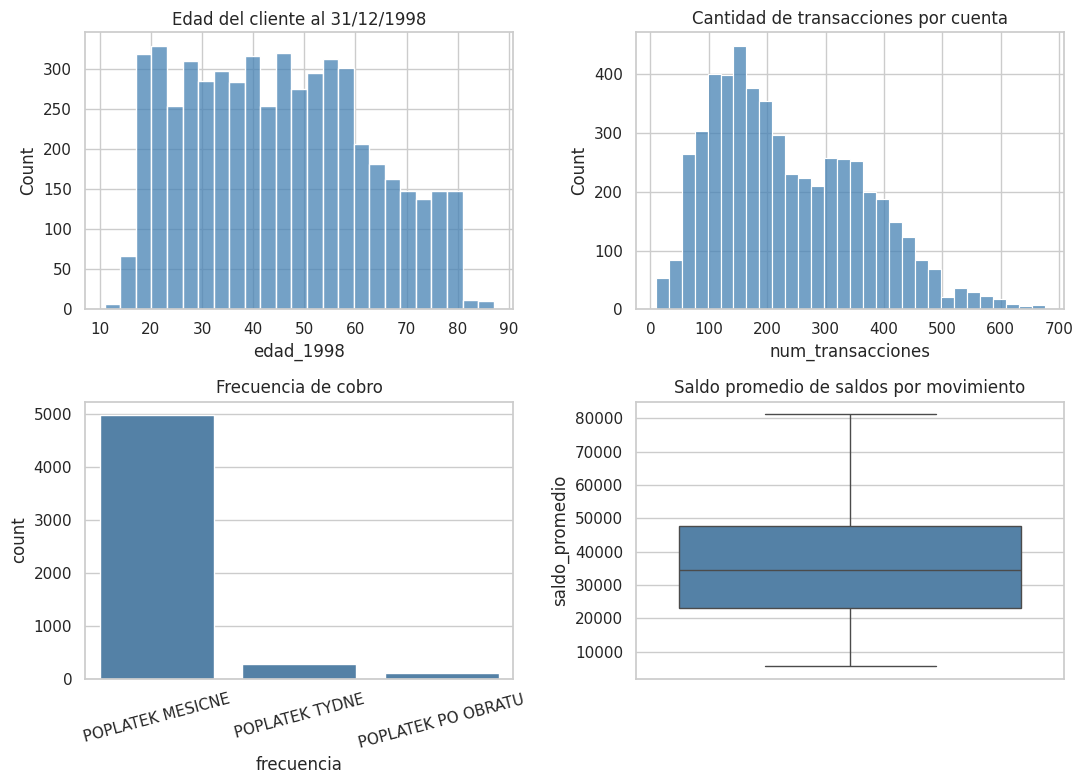

In [6]:
fig, ejes = plt.subplots(2,2,figsize=(11,8))
sns.histplot(data=df,x='edad_1998',bins=25,ax=ejes[0,0],color='steelblue')
ejes[0,0].set_title('Edad del cliente al 31/12/1998')
sns.histplot(data=df,x='num_transacciones',bins=30,ax=ejes[0,1],color='steelblue')
ejes[0,1].set_title('Cantidad de transacciones por cuenta')
sns.countplot(data=df,x='frecuencia',ax=ejes[1,0],color='steelblue')
ejes[1,0].tick_params(axis='x',rotation=15)
ejes[1,0].set_title('Frecuencia de cobro')
sns.boxplot(data=df,y='saldo_promedio',ax=ejes[1,1],showfliers=False,color='steelblue')
ejes[1,1].set_title('Saldo promedio de saldos por movimiento')
fig.tight_layout()
fig.savefig(GRAFICOS/'02_resumen_univariado.png',dpi=140)
plt.show()
plt.close(fig)

In [7]:
# Salidas individuales: se pueden usar como evidencia en el informe.
for variable in cuantitativas:
    fig, ax = plt.subplots(figsize=(7,4))
    df[variable].dropna().hist(bins=30,ax=ax)
    ax.set_title(f'Distribución de {variable}')
    ax.set_xlabel(variable)
    ax.set_ylabel('Frecuencia')
    fig.tight_layout()
    fig.savefig(GRAFICOS/f'02_hist_{variable}.png',dpi=120)
    plt.close(fig)

for variable in cualitativas:
    fig, ax = plt.subplots(figsize=(7,4))
    df[variable].value_counts(dropna=False).plot.bar(ax=ax)
    ax.set_title(f'Frecuencia de {variable}')
    ax.set_xlabel(variable)
    ax.set_ylabel('Clientes')
    ax.tick_params(axis='x',rotation=15)
    fig.tight_layout()
    fig.savefig(GRAFICOS/f'02_barras_{variable}.png',dpi=120)
    plt.close(fig)
print('Se guardaron',len(cuantitativas),'histogramas y',len(cualitativas),'gráficos de barras.')

Se guardaron 8 histogramas y 4 gráficos de barras.


## 7. Hallazgos para el informe
Utiliza el `diccionario`, las tablas de estadística y los gráficos para responder:
- ¿Qué tipos y cantidades de variables existen?
- ¿Qué variables presentan mayor dispersión?
- ¿Existen nulos, categorías desequilibradas o fechas no válidas?

**Importante:** estadísticos sobre IDs no tienen interpretación de negocio; los valores históricos y monetarios no deben considerarse actuales.

In [8]:
print('Variables estudiadas:',len(df.columns))
print('Porcentaje con tarjeta:',round(100*df['tiene_tarjeta'].mean(),2))
print('Top 5 de variables con más nulos (%):')
display(diccionario.sort_values('nulos_pct',ascending=False).head(5))

Variables estudiadas: 22
Porcentaje con tarjeta: 16.61
Top 5 de variables con más nulos (%):


,variable,tipo_analitico,tipo_pandas,nulos,nulos_pct,valores_distintos
15,fecha_primera_tarjeta,fecha,datetime64[ns],4477,83.39,607
0,client_id,identificador/código,int64,0,0.00,5369
2,district_id_cliente,identificador/código,int64,0,0.00,77
3,sexo,cualitativa,object,0,0.00,2
4,fecha_nacimiento,fecha,datetime64[ns],0,0.00,4738
